# Assignment 7: Facebook Ad Conversions - EDA, Feature Scaling, Polynomial Features, and Regression Models

In this assignment, I will predict the number of conversions (people who enquired about a product) from Facebook ad campaign data. I will practise exploratory data analysis (EDA), feature scaling, polynomial feature engineering, and regression modelling.

I used the Facebook ad campaign dataset (KAG_conversion_data.csv) from Kaggle instead of the Wine dataset. The Wine target is a class (0, 1, 2), while this dataset has a true numeric target, which makes it a better fit for Linear Regression, Lasso Regression, and RMSE (Root Mean Squared Error). It also connects to my background in digital marketing.

My steps:
- Load the dataset and split it into 80% training and 20% testing
- Explore the training data with summary statistics and visualizations
- Scale the features with StandardScaler
- Create degree 2 polynomial features
- Train a Linear Regression model and evaluate it with RMSE
- Train a Lasso Regression model and compare the results

## Step 1: Load the Dataset and Split into Training and Test Sets

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
pd.set_option("display.max_columns", None)

In [3]:
# Load the data
ads_df = pd.read_csv("KAG_conversion_data.csv")
print("Shape:", ads_df.shape)
display(ads_df.head())

Shape: (1143, 11)


,ad_id,xyz_campaign_id,fb_campaign_id,age,gender,interest,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion
0,708746,916,103916,30-34,M,15,7350,1,1.43,2,1
1,708749,916,103917,30-34,M,16,17861,2,1.82,2,0
2,708771,916,103920,30-34,M,20,693,0,0.00,1,0
3,708815,916,103928,30-34,M,28,4259,1,1.25,1,0
4,708818,916,103928,30-34,M,28,4133,1,1.29,1,1


In [4]:
# Unique values per column (helps decide which columns are IDs or categories)
print("Unique values per column:")
print(ads_df.nunique())
print("\nMissing values:", ads_df.isnull().sum().sum())

Unique values per column:
ad_id                  1143
xyz_campaign_id           3
fb_campaign_id          691
age                       4
gender                    2
interest                 40
Impressions            1130
Clicks                  183
Spent                   869
Total_Conversion         32
Approved_Conversion      16
dtype: int64

Missing values: 0


### Interpretation

The dataset has 1,143 ads and 11 columns, with no missing values. Each row is one Facebook ad.

From the unique values:
- ad_id (1,143 unique) and fb_campaign_id (691 unique) are ID numbers, so they do not help predict conversions. I will drop them.
- xyz_campaign_id has only 3 values, so it shows which of the 3 campaigns the ad belongs to. I will keep it as a category.
- age has 4 groups (30-34, 35-39, 40-44, 45-49) and gender has 2 values (M and F). Both are text, so they need encoding.
- interest is the Facebook interest category the ad targeted. Its 40 numbers are labels, not amounts. One-hot encoding it would add 39 columns, and polynomial features would then create far too many features for this dataset, so I will drop it.
- Approved_Conversion (people who bought) happens at the same time as the target, so using it as a feature would be data leakage. I will drop it.
- The target is Total_Conversion, the number of people who enquired after seeing the ad.

### 1B: Remove Unneeded Columns and Split

In [5]:
# Structure fixes: drop ID columns, interest, and Approved_Conversion (leakage)
ads = ads_df.drop(columns=["ad_id", "fb_campaign_id", "interest", "Approved_Conversion"])

# Campaign ID is a category, not an amount
ads["xyz_campaign_id"] = ads["xyz_campaign_id"].astype(str)

# Separate features and target, then split 80/20
X = ads.drop("Total_Conversion", axis=1)
y = ads["Total_Conversion"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (914, 6) | X_test: (229, 6)


## Step 2: Exploratory Data Analysis (Training Data)

### 2A: Basic Information

In [6]:
# Put features and target together for EDA (training data only)
train_df = X_train.copy()
train_df["Total_Conversion"] = y_train

train_df.info()
display(train_df.describe().round(2))




<class 'pandas.DataFrame'>
Index: 914 entries, 12 to 1126
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   xyz_campaign_id   914 non-null    str    
 1   age               914 non-null    str    
 2   gender            914 non-null    str    
 3   Impressions       914 non-null    int64  
 4   Clicks            914 non-null    int64  
 5   Spent             914 non-null    float64
 6   Total_Conversion  914 non-null    int64  
dtypes: float64(1), int64(3), str(3)
memory usage: 66.0 KB


,Impressions,Clicks,Spent,Total_Conversion
count,914.00,914.00,914.00,914.00
mean,191769.02,34.36,52.86,2.88
std,316675.61,58.06,88.79,4.52
min,87.00,0.00,0.00,0.00
25%,7104.75,1.00,1.53,1.00
50%,57140.00,9.00,13.54,1.00
75%,231997.50,39.00,62.12,3.00
max,3052003.00,421.00,639.95,60.00


In [7]:
# Categorical columns
for col in ["xyz_campaign_id", "age", "gender"]:
    print(f"\n{col}:")
    print(train_df[col].value_counts())


xyz_campaign_id:
xyz_campaign_id
1178    511
936     358
916      45
Name: count, dtype: int64

age:
age
30-34    333
45-49    211
35-39    209
40-44    161
Name: count, dtype: int64

gender:
gender
M    470
F    444
Name: count, dtype: int64


### Interpretation

The training set has 914 ads. There are no missing values. xyz_campaign_id, age, and gender are text (categories), and Impressions, Clicks, Spent, and Total_Conversion are numbers.

- All numeric columns are strongly right-skewed. For each one, the standard deviation is larger than the mean, and the mean is much higher than the median. For example, Impressions has a median of 57,140 but a mean of 191,769 and a maximum of over 3 million. A few very large ads pull the averages up.
- Clicks range from 0 to 421 (median 9), and Spent ranges from $0 to $639.95 (median $13.54).
- The target, Total_Conversion, has a median of 1 and 75% of ads have 3 or fewer conversions, but the maximum is 60.
- Some ads have 0 clicks and $0 spent. These are likely real ads that barely ran, not errors.
- Campaign 1178 has 511 ads, campaign 936 has 358, and campaign 916 has only 45.
- The 30-34 age group has the most ads (333), and gender is almost balanced (470 male, 444 female).

### 2B: Correlation Heatmap

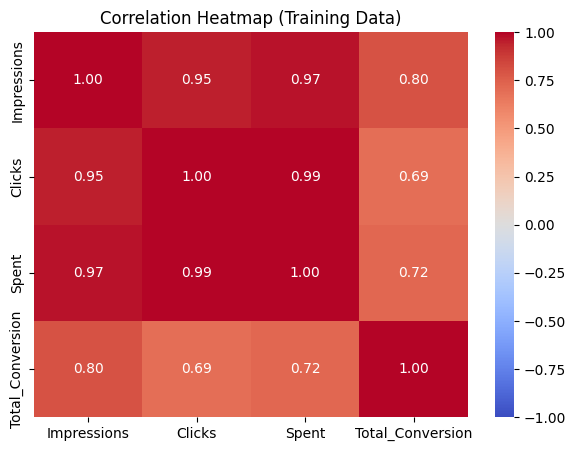

In [8]:
num_cols = ["Impressions", "Clicks", "Spent", "Total_Conversion"]

plt.figure(figsize=(7, 5))
sns.heatmap(train_df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap (Training Data)")
plt.show()


### Interpretation

- Impressions has the strongest correlation with Total_Conversion (0.80), followed by Spent (0.72) and Clicks (0.69). Interestingly, impressions matter more than clicks, which suggests some people enquire after seeing an ad without clicking it.
- Impressions, Clicks, and Spent are very strongly correlated with each other (0.95 to 0.99). This makes sense, because spending more shows the ad to more people, who then click more. However, it means these features carry almost the same information (multicollinearity), which can make Linear Regression coefficients unreliable.

### 2C: Pairplot

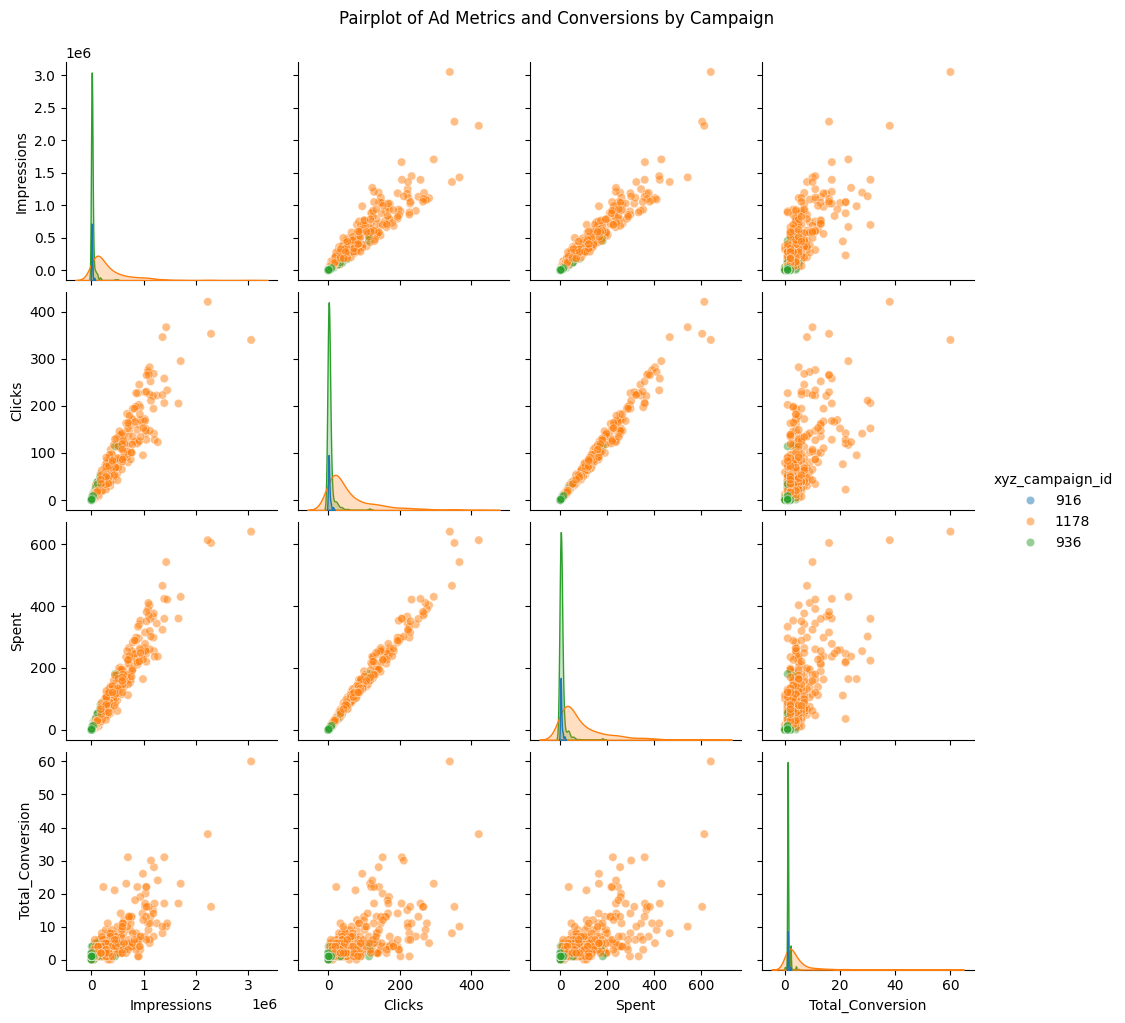

In [9]:
sns.pairplot(train_df, vars=num_cols, hue="xyz_campaign_id", plot_kws={"alpha": 0.5})
plt.suptitle("Pairplot of Ad Metrics and Conversions by Campaign", y=1.02)
plt.show()

### Interpretation

- Campaign 1178 (orange) contains almost all of the large ads, with high impressions, clicks, and spending. Campaigns 916 and 936 have much smaller ads, grouped near zero.
- Clicks and Spent form an almost perfect straight line, which matches their 0.99 correlation (each click costs a fairly similar amount).
- Conversions increase as impressions, clicks, and spending increase, but the points spread out more for larger ads. Big ads can have very different results, so they will be harder to predict.
- There is one ad with about 3 million impressions and 60 conversions, far away from the rest.

### 2D: Distribution of the Target (Total_Conversion)

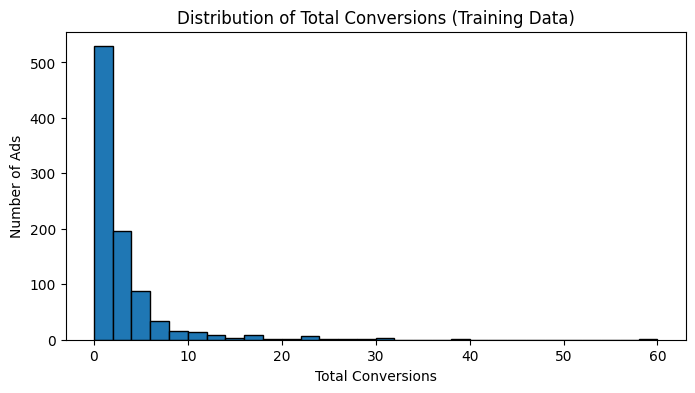

In [10]:
plt.figure(figsize=(8, 4))
plt.hist(train_df["Total_Conversion"], bins=30, edgecolor="black")
plt.xlabel("Total Conversions")
plt.ylabel("Number of Ads")
plt.title("Distribution of Total Conversions (Training Data)")
plt.show()

### Interpretation

The target is strongly right-skewed. Most ads have only 0 to 2 conversions (over 500 ads in the first bar), and very few ads have more than 10. A small number of ads reach 20 to 60 conversions. Because the target is so skewed, large errors on these few big ads will have a big effect on RMSE.

## Summary of EDA

- The data is dominated by many small ads and a few very large ones, so all numeric features and the target are strongly right-skewed.
- Impressions is the strongest single predictor of conversions (0.80), followed by Spent and Clicks.
- Impressions, Clicks, and Spent are very highly correlated with each other (0.95 to 0.99), so there is strong multicollinearity. A regularized model like Lasso may handle this better than plain Linear Regression.
- Campaign 1178 runs much larger ads than the other two campaigns, so the campaign is likely a useful feature.
- The relationship between ad activity and conversions spreads out for larger ads, so predictions for big ads will be less accurate.
- There are no missing values. The large values look like real big campaigns rather than errors, so I will not remove them.

## Step 3: Data Cleaning

### 3A: Missing Values

In [11]:
print("Missing values - train:", X_train.isnull().sum().sum(), "| test:", X_test.isnull().sum().sum())

Missing values - train: 0 | test: 0


### 3B: Outliers

In [12]:
out_cols = ["Impressions", "Clicks", "Spent"]

# Count outliers with the IQR rule (training data)
for col in out_cols:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    n_out = (X_train[col] > upper).sum()
    print(f"{col:12s} upper limit = {upper:12,.2f} | outliers: {n_out} ({n_out / len(X_train) * 100:.1f}%)")



Impressions  upper limit =   569,336.62 | outliers: 95 (10.4%)
Clicks       upper limit =        96.00 | outliers: 104 (11.4%)
Spent        upper limit =       153.01 | outliers: 103 (11.3%)


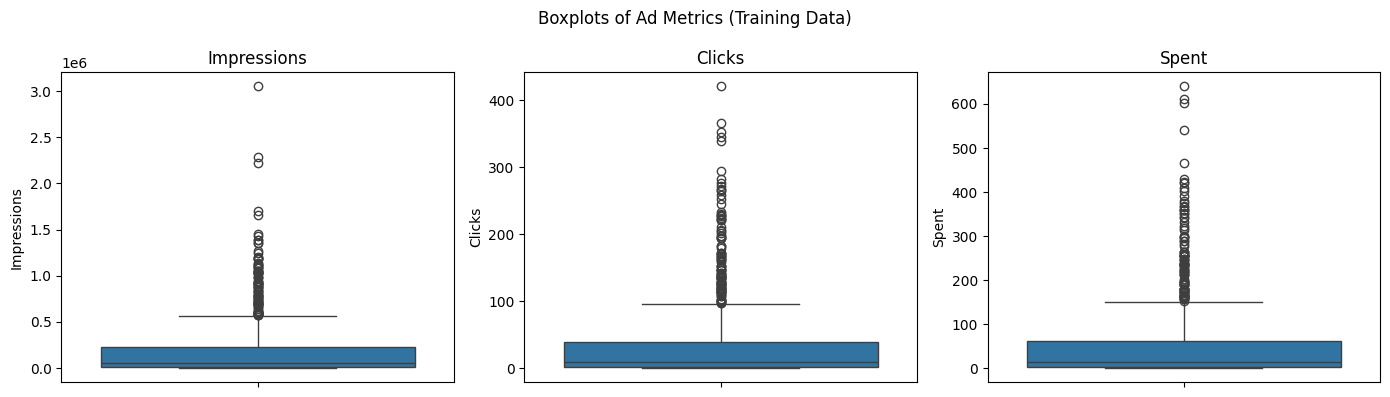

In [13]:
# Boxplots
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, out_cols):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplots of Ad Metrics (Training Data)")
plt.tight_layout()
plt.show()

### Interpretation

Missing values: there are no missing values in the training or test set, so no imputation is needed.

Outliers: using the IQR rule on the training data, about 10% to 11% of ads are outliers in each column:
- Impressions: 95 ads above 569,337 (10.4%)
- Clicks: 104 ads above 96 clicks (11.4%)
- Spent: 103 ads above $153.01 (11.3%)

The boxplots show the box squeezed near zero with a long line of outliers above it, which matches the strong right skew.

I decided not to remove or cap these outliers. Over 10% of the ads are affected, and they are real large ads (mostly from campaign 1178), not data errors. Removing them would delete the most important campaigns, and capping would make many different large ads look the same. Instead, I will apply a log transformation in the next step. This keeps every ad but reduces the skew.

## Step 4: Feature Engineering

### 4A: New Marketing Metrics (CTR, CPC, CPM)

In [14]:
# Same new columns in train and test (row-by-row formulas, nothing learned from data)
def add_marketing_features(data):
    data = data.copy()
    data["CTR"] = np.where(data["Impressions"] > 0, data["Clicks"] / data["Impressions"] * 100, 0)
    data["CPC"] = np.where(data["Clicks"] > 0, data["Spent"] / data["Clicks"], 0)
    data["CPM"] = np.where(data["Impressions"] > 0, data["Spent"] / data["Impressions"] * 1000, 0)
    return data

X_train = add_marketing_features(X_train)
X_test = add_marketing_features(X_test)

display(X_train[["CTR", "CPC", "CPM"]].describe().round(3))

,CTR,CPC,CPM
count,914.000,914.000,914.000
mean,0.017,1.237,0.242
std,0.012,0.610,0.163
min,0.000,0.000,0.000
25%,0.010,1.267,0.154
50%,0.016,1.453,0.249
75%,0.023,1.600,0.333
max,0.106,2.212,1.504


### Interpretation

I created three common digital marketing metrics from the raw values, in both the training and test sets:
- CTR (Click-Through Rate) = Clicks / Impressions x 100: how engaging the ad is
- CPC (Cost per Click) = Spent / Clicks: how expensive each click is
- CPM (Cost per Mille) = Spent / Impressions x 1000: the cost of showing the ad 1,000 times

These are row-by-row formulas, so nothing is learned from the data and there is no leakage. When an ad had 0 clicks or 0 impressions, I set the metric to 0 to avoid dividing by zero.

I did not create CPL (Cost per Lead) or CPA (Cost per Acquisition), because they are calculated using conversions. Since conversions are what I am trying to predict, using them as features would be data leakage.

### 4B: Log Transformation of Skewed Features

In [15]:
log_cols = ["Impressions", "Clicks", "Spent"]

print("Skewness before:")
print(X_train[log_cols].skew().round(2))

Skewness before:
Impressions    3.04
Clicks         2.75
Spent          2.76
dtype: float64


In [16]:
for col in log_cols:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])

print("\nSkewness after log1p:")
print(X_train[log_cols].skew().round(2))


Skewness after log1p:
Impressions   -0.35
Clicks         0.15
Spent          0.04
dtype: float64


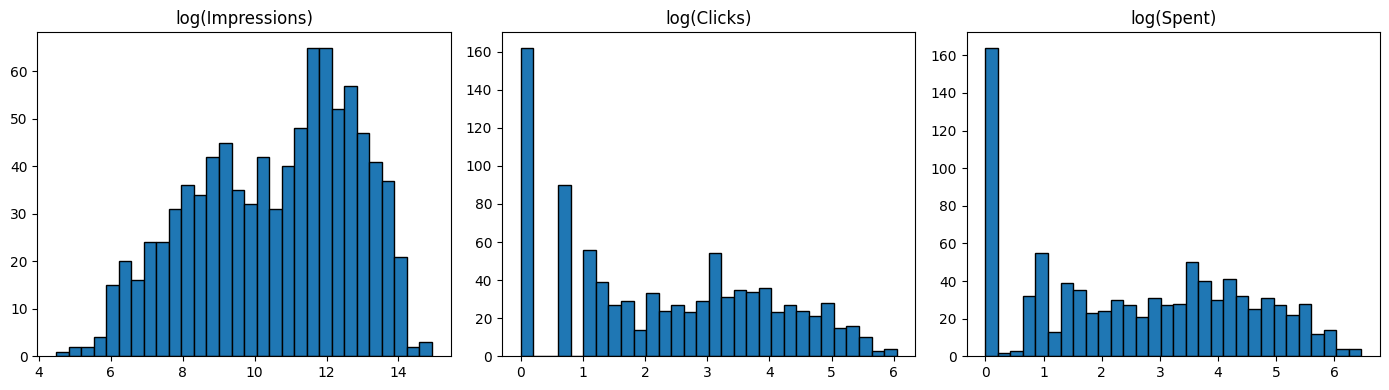

In [17]:
# Histograms after transformation
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, log_cols):
    ax.hist(X_train[col], bins=30, edgecolor="black")
    ax.set_title(f"log({col})")
plt.tight_layout()
plt.show()

### Interpretation

I applied a log transformation (log1p, which is log(x + 1)) to Impressions, Clicks, and Spent in both sets. I used log1p because some ads have 0 clicks or $0 spent, and the log of 0 is undefined.

Skewness (0 means symmetric):
- Impressions: from 3.04 to -0.35
- Clicks: from 2.75 to 0.15
- Spent: from 2.76 to 0.04

The skew is now close to 0 for all three columns, so the very large ads no longer dominate. log(Impressions) now looks close to a bell shape. Clicks and Spent have a tall bar at 0, which represents about 160 ads with no clicks and no spending. The log cannot spread these out because they are all exactly zero.

## Step 5: Encoding and Feature Scaling

### 5A: One-Hot Encoding

In [18]:
cat_cols = ["xyz_campaign_id", "age", "gender"]

X_train_enc = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test_enc = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

# Test must have exactly the same columns as train
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

print("Train:", X_train_enc.shape, "| Test:", X_test_enc.shape)
print("New columns:", [c for c in X_train_enc.columns if c not in X_train.columns])

Train: (914, 12) | Test: (229, 12)
New columns: ['xyz_campaign_id_916', 'xyz_campaign_id_936', 'age_35-39', 'age_40-44', 'age_45-49', 'gender_M']


### Interpretation

I one-hot encoded the three categorical columns, using drop_first=True to avoid repeating information:
- xyz_campaign_id became xyz_campaign_id_916 and xyz_campaign_id_936. Campaign 1178 is the baseline (both columns are 0).
- age became age_35-39, age_40-44, and age_45-49. The 30-34 group is the baseline (all three are 0).
- gender became gender_M. Female is the baseline (gender_M = 0).

Both the training set (914 ads) and the test set (229 ads) now have the same 12 columns.

### 5B: Feature Scaling with StandardScaler

In [19]:
scale_cols = ["Impressions", "Clicks", "Spent", "CTR", "CPC", "CPM"]

X_train_scaled = X_train_enc.copy()
X_test_scaled = X_test_enc.copy()

scaler = StandardScaler()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train_enc[scale_cols])   # learn from train
X_test_scaled[scale_cols] = scaler.transform(X_test_enc[scale_cols])         # apply to test

# First 5 rows of the scaled features
display(X_train_scaled.head())
print(X_train_scaled[scale_cols].describe().loc[["mean", "std"]].round(2))

,Impressions,Clicks,Spent,CTR,CPC,CPM,xyz_campaign_id_916,xyz_campaign_id_936,age_35-39,age_40-44,age_45-49,gender_M
12,-0.911017,-1.371452,-1.418248,-1.419798,-2.028165,-1.487080,1,0,0,0,0,1
758,1.141988,1.186363,1.248367,-0.075978,0.938856,0.257714,0,0,0,0,1,1
636,0.311707,-0.011501,0.072359,-0.409270,0.636507,-0.308728,0,0,1,0,0,1
1109,1.138861,1.279623,1.213868,0.167887,0.343514,0.160714,0,0,1,0,0,0
743,0.766333,0.761226,0.817374,0.059958,0.738504,0.304474,0,0,0,1,0,1


      Impressions  Clicks  Spent  CTR  CPC  CPM
mean          0.0     0.0    0.0 -0.0 -0.0 -0.0
std           1.0     1.0    1.0  1.0  1.0  1.0


### Interpretation

I scaled the 6 continuous features (Impressions, Clicks, Spent, CTR, CPC, and CPM) with StandardScaler. The scaler learned the mean and standard deviation from the training set and used the same values to scale the test set. The 0/1 dummy columns were not scaled.

After scaling, each of the 6 columns has a mean of 0 and a standard deviation of 1 in the training set. In the first rows, the values now show how far each ad is above or below the average. For example, ad 12 has negative values for every metric, which means it is a small, low-cost ad. Ad 758 has positive values, which means it is a large ad.

### Why feature scaling is important
- Features on different scales can mislead models. Before scaling, CPM was a small number while Impressions was in the thousands, so large-valued features could dominate.
- Models that use distances, like KNN and SVM, need scaling so every feature is treated fairly.
- Regularized models like Lasso (used later) need scaling, because the penalty is applied to coefficients. Without scaling, features with small numbers get much larger coefficients and are penalized unfairly.
- Polynomial features (the next step) multiply features together, so unscaled values would become extremely large numbers.

## Step 6: Polynomial Features (Degree 2)

In [20]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

poly_names = poly.get_feature_names_out(X_train_scaled.columns)
X_train_poly_df = pd.DataFrame(X_train_poly, columns=poly_names, index=X_train_scaled.index)

print("Before:", X_train_scaled.shape, "| After:", X_train_poly_df.shape)
print("Test after:", X_test_poly.shape)
print("\nExample new features:", list(poly_names[12:20]))
display(X_train_poly_df.head())

Before: (914, 12) | After: (914, 90)
Test after: (229, 90)

Example new features: ['Impressions^2', 'Impressions Clicks', 'Impressions Spent', 'Impressions CTR', 'Impressions CPC', 'Impressions CPM', 'Impressions xyz_campaign_id_916', 'Impressions xyz_campaign_id_936']


,Impressions,Clicks,Spent,CTR,CPC,CPM,xyz_campaign_id_916,xyz_campaign_id_936,age_35-39,age_40-44,age_45-49,gender_M,Impressions^2,Impressions Clicks,Impressions Spent,Impressions CTR,Impressions CPC,Impressions CPM,Impressions xyz_campaign_id_916,Impressions xyz_campaign_id_936,Impressions age_35-39,Impressions age_40-44,Impressions age_45-49,Impressions gender_M,Clicks^2,Clicks Spent,Clicks CTR,Clicks CPC,Clicks CPM,Clicks xyz_campaign_id_916,Clicks xyz_campaign_id_936,Clicks age_35-39,Clicks age_40-44,Clicks age_45-49,Clicks gender_M,Spent^2,Spent CTR,Spent CPC,Spent CPM,Spent xyz_campaign_id_916,Spent xyz_campaign_id_936,Spent age_35-39,Spent age_40-44,Spent age_45-49,Spent gender_M,CTR^2,CTR CPC,CTR CPM,CTR xyz_campaign_id_916,CTR xyz_campaign_id_936,CTR age_35-39,CTR age_40-44,CTR age_45-49,CTR gender_M,CPC^2,CPC CPM,CPC xyz_campaign_id_916,CPC xyz_campaign_id_936,CPC age_35-39,CPC age_40-44,CPC age_45-49,CPC gender_M,CPM^2,CPM xyz_campaign_id_916,CPM xyz_campaign_id_936,CPM age_35-39,CPM age_40-44,CPM age_45-49,CPM gender_M,xyz_campaign_id_916^2,xyz_campaign_id_916 xyz_campaign_id_936,xyz_campaign_id_916 age_35-39,xyz_campaign_id_916 age_40-44,xyz_campaign_id_916 age_45-49,xyz_campaign_id_916 gender_M,xyz_campaign_id_936^2,xyz_campaign_id_936 age_35-39,xyz_campaign_id_936 age_40-44,xyz_campaign_id_936 age_45-49,xyz_campaign_id_936 gender_M,age_35-39^2,age_35-39 age_40-44,age_35-39 age_45-49,age_35-39 gender_M,age_40-44^2,age_40-44 age_45-49,age_40-44 gender_M,age_45-49^2,age_45-49 gender_M,gender_M^2
12,-0.911017,-1.371452,-1.418248,-1.419798,-2.028165,-1.487080,1.0,0.0,0.0,0.0,0.0,1.0,0.829952,1.249416,1.292048,1.293460,1.847692,1.354755,-0.911017,-0.0,-0.000000,-0.000000,-0.000000,-0.911017,1.880880,1.945059,1.947185,2.781530,2.039458,-1.371452,-0.0,-0.000000,-0.000000,-0.000000,-1.371452,2.011429,2.013626,2.876442,2.109049,-1.418248,-0.0,-0.000000,-0.000000,-0.000000,-1.418248,2.015827,2.879585,2.111353,-1.419798,-0.0,-0.000000,-0.000000,-0.000000,-1.419798,4.113453,3.016043,-2.028165,-0.0,-0.000000,-0.000000,-0.000000,-2.028165,2.211407,-1.48708,-0.0,-0.000000,-0.000000,-0.000000,-1.487080,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
758,1.141988,1.186363,1.248367,-0.075978,0.938856,0.257714,0.0,0.0,0.0,0.0,1.0,1.0,1.304137,1.354812,1.425620,-0.086766,1.072162,0.294307,0.000000,0.0,0.000000,0.000000,1.141988,1.141988,1.407457,1.481016,-0.090138,1.113823,0.305743,0.000000,0.0,0.000000,0.000000,1.186363,1.186363,1.558420,-0.094849,1.172036,0.321722,0.000000,0.0,0.000000,0.000000,1.248367,1.248367,0.005773,-0.071333,-0.019581,-0.000000,-0.0,-0.000000,-0.000000,-0.075978,-0.075978,0.881450,0.241957,0.000000,0.0,0.000000,0.000000,0.938856,0.938856,0.066417,0.00000,0.0,0.000000,0.000000,0.257714,0.257714,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
636,0.311707,-0.011501,0.072359,-0.409270,0.636507,-0.308728,0.0,0.0,1.0,0.0,0.0,1.0,0.097161,-0.003585,0.022555,-0.127572,0.198404,-0.096233,0.000000,0.0,0.311707,0.000000,0.000000,0.311707,0.000132,-0.000832,0.004707,-0.007320,0.003551,-0.000000,-0.0,-0.011501,-0.000000,-0.000000,-0.011501,0.005236,-0.029614,0.046057,-0.022339,0.000000,0.0,0.072359,0.000000,0.000000,0.072359,0.167502,-0.260503,0.126353,-0.000000,-0.0,-0.409270,-0.000000,-0.000000,-0.409270,0.405141,-0.196508,0.000000,0.0,0.636507,0.000000,0.000000,0.636507,0.095313,-0.00000,-0.0,-0.308728,-0.000000,-0.000000,-0.308728,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1109,1.138861,1.279623,1.213868,0.167887,0.343514,0.160714,0.0,0.0,1.0,0.0,0.0,0.0,1.297004,1.457313,1.382427,0.191200,0.391215,0.183031,0.000000,0.0,1.138861,0.000000,0.000000,0.000000,1.637436,1.553294,0.214832,0.439569,0.205654,0.000000,0.0,1.279623,0.000000,0.000000,0.000000,1.473476,0.203793,0.416981,0.195086,0.000000,0.0,1.213868,0.000000,0.000000,0.000000,0.028186,0.057672,0.026982,0.000000,0.0,0.167887,0.000000,0.000000,0.000000

### Interpretation

I used PolynomialFeatures with degree 2, which increased the number of features from 12 to 90 in both sets:
- 12 original features
- 12 squared features (for example, Impressions^2)
- 66 interaction features, where two features are multiplied together (for example, Impressions Clicks = Impressions x Clicks)

Some of the new features are not useful. Squaring a 0/1 column gives the same column (gender_M^2 = gender_M), and some interactions are always 0, such as age_35-39 x age_40-44, because an ad can only target one age group.

### How polynomial features can impact model performance
- Benefit: they let a linear model capture curved relationships and combined effects. For example, the effect of spending more might depend on how engaging the ad is (Spent x CTR).
- Risk: the number of features grows quickly (from 12 to 90 here). With more features, the model can fit noise in the training data instead of the real pattern, which leads to overfitting.
- Many new features are highly correlated with each other, which makes multicollinearity worse and can make Linear Regression unstable.
- Regularization, like Lasso, can help by removing the features that are not useful.

## Step 7: Linear Regression Model

In [21]:
def evaluate(model, X_tr, X_te, name):
    model.fit(X_tr, y_train)
    pred_train = model.predict(X_tr)
    pred_test = model.predict(X_te)
    return {
        "Model": name,
        "Features": X_tr.shape[1],
        "Train RMSE": round(np.sqrt(mean_squared_error(y_train, pred_train)), 3),
        "Test RMSE": round(np.sqrt(mean_squared_error(y_test, pred_test)), 3),
        "Train R²": round(r2_score(y_train, pred_train), 3),
        "Test R²": round(r2_score(y_test, pred_test), 3)
    }

In [22]:
results = []

# Baseline: Linear Regression on the 12 scaled features (no polynomial)
results.append(evaluate(LinearRegression(), X_train_scaled, X_test_scaled, "Linear Regression (12 features)"))

# Required: Linear Regression on the 90 polynomial features
lin_poly = LinearRegression()
results.append(evaluate(lin_poly, X_train_poly, X_test_poly, "Linear Regression + Polynomial (90 features)"))

print(pd.DataFrame(results).to_string(index=False))

                                       Model  Features  Train RMSE  Test RMSE  Train R²  Test R²
             Linear Regression (12 features)        12       3.510      3.244     0.396    0.442
Linear Regression + Polynomial (90 features)        90       2.502      2.171     0.693    0.750


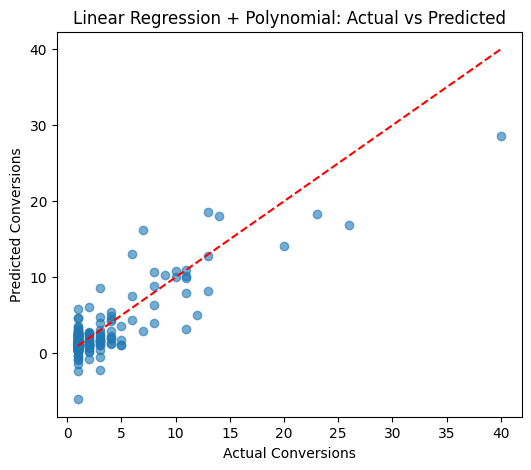

In [23]:
# Actual vs predicted (polynomial model)
y_pred_poly = lin_poly.predict(X_test_poly)
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_poly, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Conversions")
plt.ylabel("Predicted Conversions")
plt.title("Linear Regression + Polynomial: Actual vs Predicted")
plt.show()

### Interpretation

I trained two Linear Regression models: a baseline using the 12 scaled features, and the required model using the 90 polynomial features.

- Baseline (12 features): test RMSE 3.24 conversions, test R² 0.44
- Polynomial (90 features): test RMSE 2.17 conversions, test R² 0.75

RMSE (Root Mean Squared Error) is the average prediction error in conversions. The polynomial model's predictions are off by about 2.2 conversions on average, which is 33% less error than the baseline. It also explains 75% of the variation in conversions, compared to 44%.

The polynomial features helped because I log-transformed the features but kept the target in its original units. This made the relationship curved, and the squared and interaction terms allow the model to follow that curve.

There is no sign of overfitting. The test RMSE (2.17) is slightly lower than the training RMSE (2.50). This is likely because the most extreme ad (60 conversions) is in the training set, which increases the training error.

From the actual vs predicted chart:
- Small ads (under 5 conversions) are predicted fairly closely.
- The model predicts some negative conversions (as low as -6), which is impossible.
- Large ads are underpredicted. For example, an ad with 40 conversions was predicted at about 28.

### Reflection and suggested improvements
- Log-transform the target as well, then convert predictions back. This would reduce the effect of the few very large ads and prevent negative predictions.
- Set any negative predictions to 0, since conversions cannot be negative.
- Use regularization (Lasso or Ridge) to remove or shrink the many unhelpful polynomial features.
- Use cross-validation instead of a single test split, for a more reliable comparison.
- Try models that handle non-linear patterns naturally, such as Random Forest, or models designed for count data, such as Poisson regression.

## Step 8: Lasso Regression and Model Comparison

In [24]:
from sklearn.model_selection import GridSearchCV

# Find the best alpha with 5-fold cross-validation on the training data
lasso_grid = GridSearchCV(
    Lasso(max_iter=50000),
    {"alpha": [0.001, 0.01, 0.05, 0.1, 0.5, 1]},
    cv=5, scoring="neg_root_mean_squared_error"
)
lasso_grid.fit(X_train_poly, y_train)

cv_table = pd.DataFrame(lasso_grid.cv_results_)[["param_alpha", "mean_test_score"]]
cv_table["CV RMSE"] = (-cv_table["mean_test_score"]).round(3)
print(cv_table[["param_alpha", "CV RMSE"]].to_string(index=False))
best_alpha = lasso_grid.best_params_["alpha"]
print("\nBest alpha:", best_alpha)


C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.228e+00, tolerance: 1.452e+00
  model = cd_fast.enet_coordinate_descent(


 param_alpha  CV RMSE
       0.001    2.711
       0.010    2.806
       0.050    2.937
       0.100    3.038
       0.500    3.320
       1.000    3.654

Best alpha: 0.001


In [25]:
# Lasso on polynomial features (best alpha) and on the 12 scaled features
lasso_poly = Lasso(alpha=best_alpha, max_iter=50000)
results.append(evaluate(lasso_poly, X_train_poly, X_test_poly, f"Lasso + Polynomial (alpha={best_alpha})"))
results.append(evaluate(Lasso(alpha=best_alpha, max_iter=50000), X_train_scaled, X_test_scaled,
                        f"Lasso (12 features, alpha={best_alpha})"))

print("\n", pd.DataFrame(results).to_string(index=False))

# How many polynomial features did Lasso keep?
kept = (lasso_poly.coef_ != 0).sum()
print(f"\nLasso kept {kept} of {len(lasso_poly.coef_)} polynomial features (the rest were set to 0)")


                                        Model  Features  Train RMSE  Test RMSE  Train R²  Test R²
             Linear Regression (12 features)        12       3.510      3.244     0.396    0.442
Linear Regression + Polynomial (90 features)        90       2.502      2.171     0.693    0.750
            Lasso + Polynomial (alpha=0.001)        90       2.561      2.206     0.678    0.742
            Lasso (12 features, alpha=0.001)        12       3.511      3.240     0.395    0.444

Lasso kept 62 of 90 polynomial features (the rest were set to 0)


### Interpretation

I used 5-fold cross-validation on the training data to choose Lasso's alpha (regularization strength). The cross-validation RMSE got worse as alpha increased, from 2.71 at alpha = 0.001 to 3.65 at alpha = 1. The best alpha was 0.001, the smallest value I tested. This means the model performs best with very little regularization, so the polynomial model was not strongly overfitting. Since 0.001 is at the edge of my grid, testing even smaller values could be a next step.

Results on the test set:
- Linear Regression (12 features): RMSE 3.24, R² 0.44
- Linear Regression + Polynomial (90 features): RMSE 2.17, R² 0.75
- Lasso + Polynomial: RMSE 2.21, R² 0.74
- Lasso (12 features): RMSE 3.24, R² 0.44

Lasso kept 62 of the 90 polynomial features and set the other 28 coefficients to 0. Many of the removed features were likely the useless ones, such as squared 0/1 columns or interactions that are always 0.

### Which model performed best and why?
Linear Regression with polynomial features had the lowest test RMSE (2.17), but Lasso with polynomial features was almost the same (2.21) while using 28 fewer features. Since the difference is very small, I would choose Lasso, because a simpler model is easier to explain and more likely to stay reliable on new data.

Both polynomial models performed much better than the models with only 12 features. This shows that the biggest improvement came from adding polynomial features to capture curved relationships and interactions, not from regularization. Lasso made little difference here because the training set has 914 ads, which is enough data for 90 features without serious overfitting.